#YOLO

## Tải thư viện Ultralytics

In [1]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 14.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 11.7 MB/s eta 0:00:00


## Chuẩn bị thư viện
Import các thư viện cần thiết và giải nén file labels đã chuyển sang yolo dataset. Link labels: https://drive.google.com/file/d/1ZujZ32gFH7rPv0vHTSLvZqZEuIpYer5h/view?usp=sharing

In [3]:
import torch
import yaml
import os
import random
import shutil
from huggingface_hub import hf_hub_download
import xml.etree.ElementTree as ET
from ultralytics.data.utils import visualize_image_annotations
from ultralytics import YOLO
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
!unzip /content/drive/MyDrive/labels.zip -d /content/data

Streaming output truncated to the last 5000 lines.
  inflating: /content/data/labels/train/PMC6186067_3.txt  
  inflating: /content/data/labels/train/PMC6186067_5.txt  
  inflating: /content/data/labels/train/PMC6186072_2.txt  
  inflating: /content/data/labels/train/PMC6186072_3.txt  
 extracting: /content/data/labels/train/PMC6186072_4.txt  
  inflating: /content/data/labels/train/PMC6186076_3.txt  
 extracting: /content/data/labels/train/PMC6186076_5.txt  
  inflating: /content/data/labels/train/PMC6186077_10.txt  
  inflating: /content/data/labels/train/PMC6186077_5.txt  
 extracting: /content/data/labels/train/PMC6186077_6.txt  
  inflating: /content/data/labels/train/PMC6186084_2.txt  
  inflating: /content/data/labels/train/PMC6186091_1.txt  
  inflating: /content/data/labels/train/PMC6186091_2.txt  
  inflating: /content/data/labels/train/PMC6186094_2.txt  
 extracting: /content/data/labels/train/PMC6186094_5.txt  
  inflating: /content/data/labels/train/PMC6186095_3.txt  
 ext

## Setup đường dẫn và thiết bị

In [6]:
REPO_ID = "bsmock/pubtables-1m"
IMAGES_DIR = "data/images"
LABELS_DIR = "data/labels"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Tải tập hình ảnh huấn luyện của dataset, không chạy cell này nếu chỉ muốn test

In [8]:
os.makedirs("cache", exist_ok = True)
path = hf_hub_download(repo_id=REPO_ID, filename="PubTables-1M-Detection_Images_Train_Part1.tar.gz", local_dir="cache", repo_type="dataset")
dest = os.path.join(IMAGES_DIR, "train")
os.makedirs(dest, exist_ok = True)
!tar -xf {path} -C {dest}
!rm {path}
path = hf_hub_download(repo_id=REPO_ID, filename="PubTables-1M-Detection_Images_Train_Part2.tar.gz", local_dir="cache", repo_type="dataset")
!tar -xf {path} -C {dest}
!rm {path}
dest = os.path.join(IMAGES_DIR, "val")
os.makedirs(dest, exist_ok = True)
path = hf_hub_download(repo_id=REPO_ID, filename="PubTables-1M-Detection_Images_Val.tar.gz", local_dir="cache", repo_type="dataset")
!tar -xf {path} -C {dest}
!rm {path}
!rm -rf "cache"

PubTables-1M-Detection_Images_Train_Part(…): reconstructing file:   0%|          |  0.00B / 30.8GB            

PubTables-1M-Detection_Images_Train_Part(…): downloading bytes:           |  0.00B            

PubTables-1M-Detection_Images_Train_Part(…): reconstructing file:   0%|          |  0.00B / 29.3GB            

PubTables-1M-Detection_Images_Train_Part(…): downloading bytes:           |  0.00B            

PubTables-1M-Detection_Images_Val.tar.gz: reconstructing file:   0%|          |  0.00B / 7.52GB            

PubTables-1M-Detection_Images_Val.tar.gz: downloading bytes:           |  0.00B            

Tải tập hình ảnh kiểm thử của dataset

In [7]:
os.makedirs("cache", exist_ok = True)
dest = os.path.join(IMAGES_DIR, "test")
os.makedirs(dest, exist_ok = True)
path = hf_hub_download(repo_id=REPO_ID, filename="PubTables-1M-Detection_Images_Test.tar.gz", local_dir="cache", repo_type="dataset")
!tar -xf {path} -C {dest}
!rm {path}
!rm -rf "cache"

PubTables-1M-Detection_Images_Test.tar.g(…): reconstructing file:   0%|          |  0.00B / 7.44GB            

PubTables-1M-Detection_Images_Test.tar.g(…): downloading bytes:           |  0.00B            

Tải Annotation và chuyển đổi (Bỏ qua nếu đã dùng file zip)

In [ ]:
os.makedirs("cache", exist_ok = True)
dest = os.path.join(LABELS_DIR, "train")
os.makedirs(dest, exist_ok = True)
path = hf_hub_download(repo_id=REPO_ID, filename="PubTables-1M-Detection_Annotations_Train.tar.gz", local_dir="cache", repo_type="dataset")
!tar -xf {path} -C {dest}
!rm {path}
dest = os.path.join(LABELS_DIR, "val")
os.makedirs(dest, exist_ok = True)
path = hf_hub_download(repo_id=REPO_ID, filename="PubTables-1M-Detection_Annotations_Val.tar.gz", local_dir="cache", repo_type="dataset")
!tar -xf {path} -C {dest}
!rm {path}
dest = os.path.join(LABELS_DIR, "test")
os.makedirs(dest, exist_ok = True)
path = hf_hub_download(repo_id=REPO_ID, filename="PubTables-1M-Detection_Annotations_Test.tar.gz", local_dir="cache", repo_type="dataset")
!tar -xf {path} -C {dest}
!rm {path}
!rm -rf "cache"

In [ ]:
CLASS_NAME = {
    "table": 0,
    "table rotated": 1
}
def XML_to_txt(folder_path):
    for filename in os.listdir(folder_path):
        if not filename.endswith('.xml'):
            continue
        xml_path = os.path.join(folder_path, filename)
        txt_path = os.path.join(folder_path, os.path.splitext(filename)[0] + '.txt')
        with open(xml_path, 'r') as f:
            tree = ET.parse(f)
        root = tree.getroot()
        size = root.find("size")
        w = float(size.find("width").text)
        h = float(size.find("height").text)
        lines = []
        for obj in root.iter('object'):
          class_name = obj.find('name').text
          bbox = obj.find('bndbox')
          xmin = float(bbox.find('xmin').text)
          ymin = float(bbox.find('ymin').text)
          xmax = float(bbox.find('xmax').text)
          ymax = float(bbox.find('ymax').text)
          xcenter = (xmin + xmax) / (2.0 * w)
          ycenter = (ymin + ymax) / (2.0 * h)
          width = (xmax - xmin) / w
          height = (ymax - ymin) / h
          lines.append(f"{CLASS_NAME[class_name]} {xcenter:.6f} {ycenter:.6f} {width:.6f} {height:.6f}")
        with open(txt_path, "w") as f:
            f.write("\n".join(lines))
        os.remove(xml_path)
XML_to_txt(os.path.join(LABELS_DIR, "train"))
XML_to_txt(os.path.join(LABELS_DIR, "val"))
XML_to_txt(os.path.join(LABELS_DIR, "test"))

Subsample tập dữ liệu nếu không đủ tài nguyên

In [9]:
base_dir = "/content/data"
subset_sizes = {
    "train": int(len(os.listdir(os.path.join(base_dir, "images", "train"))) * 0.05),
    "val": int(len(os.listdir(os.path.join(base_dir, "images", "val"))) * 0.05),
    "test": int(len(os.listdir(os.path.join(base_dir, "images", "test"))) * 0.05),
}
random.seed(42)
for split, size in subset_sizes.items():
    src_img_dir = os.path.join(base_dir, "images", split)
    src_lbl_dir = os.path.join(base_dir, "labels", split)

    dst_img_dir = os.path.join(base_dir, "images", f"{split}_subset")
    dst_lbl_dir = os.path.join(base_dir, "labels", f"{split}_subset")

    os.makedirs(dst_img_dir, exist_ok=True)
    os.makedirs(dst_lbl_dir, exist_ok=True)

    for folder in [dst_img_dir, dst_lbl_dir]:
        if os.path.exists(folder):
            shutil.rmtree(folder)
        os.makedirs(folder, exist_ok=True)

    all_images = [f for f in os.listdir(src_img_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
    sampled_images = random.sample(all_images, min(size, len(all_images)))

    copied_count = 0
    for img_name in sampled_images:
        shutil.copy(os.path.join(src_img_dir, img_name), os.path.join(dst_img_dir, img_name))

        label_name = os.path.splitext(img_name)[0] + ".txt"
        label_path = os.path.join(src_lbl_dir, label_name)
        if os.path.exists(label_path):
            shutil.copy(label_path, os.path.join(dst_lbl_dir, label_name))

        copied_count += 1

    print(f"Created '{split}_subset' with {copied_count} images and corresponding labels.")

Created 'train_subset' with 23029 images and corresponding labels.
Created 'val_subset' with 2879 images and corresponding labels.
Created 'test_subset' with 2856 images and corresponding labels.


In [11]:
dataset_config = {
    "path": os.path.abspath("data"),
    "train": "images/train_subset",
    "val": "images/val_subset",
    "test": "images/test_subset",
    "nc": 2,
    "names": {
        0: "table",
        1: "table rotated"
    }
}
yaml_path = "data/data.yaml"
with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.dump(dataset_config, f, default_flow_style=False, sort_keys=False)

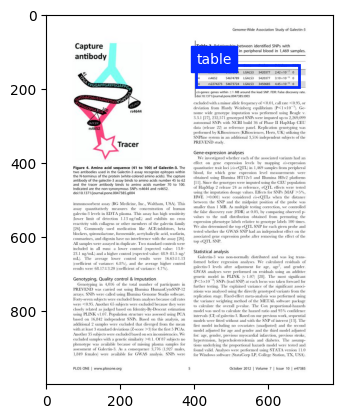

In [10]:
visualize_image_annotations(
    "data/images/train/PMC3467202_4.jpg",
    "data/labels/train/PMC3467202_4.txt",
    {0: "table", 1: "table rotated"},
)


In [ ]:
model = YOLO("yolo26n.pt")
model.train(
    data="data/data.yaml",
    epochs=10,
    imgsz=640,
    batch=128,
    device=0
)

Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=128, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, o

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7a32ca264590>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

Chạy kiểm thử trên tập test, model đã train: https://drive.google.com/file/d/1KlFpJJfXMdU_kPzoX4Fq-9qSnVqVEz5e/view?usp=sharing

In [13]:
model = YOLO("/content/best.pt")

metrics = model.val(
    data="data/data.yaml",
    split="test",
    imgsz=640,
    batch=128,
    plots=True,
    project="runs/test",
    name="evaluation",
)
print("\n===== TEST METRICS =====")
print(f"Precision : {metrics.box.mp:.4f}")
print(f"Recall    : {metrics.box.mr:.4f}")
print(f"mAP@0.5   : {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {metrics.box.map:.4f}")

print("\nPer-class mAP@0.5:0.95:")
for class_id, score in enumerate(metrics.box.maps):
    print(f"{model.names[class_id]}: {score:.4f}")


Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO26n summary (fused): 121 layers, 2,389,978 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2453.0±1058.3 MB/s, size: 141.4 KB)
val: Scanning /content/data/labels/test_subset... 2856 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2856/2856 1.4Kit/s 2.0s
val: /content/data/images/test_subset/PMC6147433_2.jpg: 1 duplicate labels removed
val: New cache created: /content/data/labels/test_subset.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 1.2it/s 18.6s
                   all       2856       3377      0.998      0.998      0.995      0.984
                 table       2841       3362      0.999      0.997      0.995      0.994
         table rotated         15         15      0.996          1      0.995      0.974
Speed: 0.9ms preprocess, 1.9ms inference, 0.0ms loss, 0.7ms postprocess pe

In [14]:
import time
import os
import shutil
from google.colab import files
from google.colab import runtime

# Thư mục chứa kết quả chạy
runs_dir = "/content/runs"
zip_path = "/content/runs.zip"

if os.path.exists(runs_dir):
    print("Đang nén thư mục runs thành runs.zip...")
    shutil.make_archive("/content/runs", "zip", runs_dir)

    print("Đang tải file runs.zip về máy tính...")
    files.download(zip_path)

    # Chờ 5 phút để quá trình tải xuống hoàn tất an toàn trước khi xóa runtime
else:
    print("Không tìm thấy thư mục runs để nén.")

Đang nén thư mục runs thành runs.zip...
Đang tải file runs.zip về máy tính...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import time
time.sleep(300)
print("Đang tiến hành tắt và xóa runtime...")
runtime.unassign()

In [12]:
import os
import shutil
from google.colab import files

# 1. Điền đường dẫn thư mục ảnh bạn muốn nén
source_dir = "/content/data/images/test_subset"

# 2. Tên file zip muốn tạo (không cần gõ đuôi .zip)
output_zip_base = "/content/test"
zip_file_path = f"{output_zip_base}.zip"

# Tiến hành kiểm tra, nén và tải về
if os.path.exists(source_dir):
    print(f"Đang nén thư mục '{source_dir}'...")
    shutil.make_archive(output_zip_base, 'zip', source_dir)

    if os.path.exists(zip_file_path):
        print(f"Nén thành công! Đang tiến hành tải file '{zip_file_path}' về máy...")
        files.download(zip_file_path)
    else:
        print("Có lỗi xảy ra: Không tìm thấy file zip sau khi nén.")
else:
    print(f"Lỗi: Không tìm thấy thư mục nguồn tại đường dẫn '{source_dir}'. Vui lòng kiểm tra lại.")

Đang nén thư mục '/content/data/images/test_subset'...
Nén thành công! Đang tiến hành tải file '/content/test.zip' về máy...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>